In [1]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    print("Folder:", root)
    for file in files:
        print("  File:", file)

Folder: /kaggle/input
Folder: /kaggle/input/datasets
Folder: /kaggle/input/datasets/blastchar
Folder: /kaggle/input/datasets/blastchar/telco-customer-churn
  File: WA_Fn-UseC_-Telco-Customer-Churn.csv


In [2]:

import pandas as pd
import numpy as np

file_path = "/kaggle/input/datasets/blastchar/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

print("\nFirst 5 records:")
display(df.head())

print("\nDataset information:")
df.info()


Dataset loaded successfully!
Shape: (7043, 21)

First 5 records:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  70

In [3]:

# 1. Check missing values
print("Missing values:")
print(df.isnull().sum())

# 2. Check duplicate records
print("\nDuplicate rows:", df.duplicated().sum())

# 3. Check target variable distribution
print("\nChurn distribution:")
print(df['Churn'].value_counts())

# 4. Check target variable percentages
print("\nChurn percentage:")
print(df['Churn'].value_counts(normalize=True) * 100)

# 5. Separate numerical and categorical columns
numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()

print("\nNumerical columns:", numerical_cols)
print("\nCategorical columns:", categorical_cols)


Missing values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Duplicate rows: 0

Churn distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn percentage:
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

Numerical columns: ['SeniorCitizen', 'tenure', 'MonthlyCharges']

Categorical columns: ['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBillin

In [4]:
data = df.copy()

data.drop('customerID', axis=1, inplace=True)

data['TotalCharges'] = pd.to_numeric(
    data['TotalCharges'], errors='coerce'
)

data['TotalCharges'] = data['TotalCharges'].fillna(0)

data['Churn'] = data['Churn'].map({'No': 0, 'Yes': 1})

X = data.drop('Churn', axis=1)
y = data['Churn']

print("Preprocessing completed!")
print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nMissing values:", data.isnull().sum().sum())
print("\nTarget distribution:")
print(y.value_counts())

Preprocessing completed!
Feature shape: (7043, 19)
Target shape: (7043,)

Missing values: 0

Target distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64


In [5]:

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

numerical_features = X.select_dtypes(include=['int64', 'float64']).columns
categorical_features = X.select_dtypes(include=['object']).columns

preprocessor = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

baseline_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(random_state=42))
])

baseline_model.fit(X_train, y_train)

y_pred = baseline_model.predict(X_test)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nBaseline Decision Tree Accuracy:",
      accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Training samples: 5634
Testing samples: 1409

Baseline Decision Tree Accuracy: 0.7196593328601846

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.80      0.81      1035
           1       0.47      0.49      0.48       374

    accuracy                           0.72      1409
   macro avg       0.64      0.65      0.65      1409
weighted avg       0.72      0.72      0.72      1409



In [6]:
from sklearn.model_selection import cross_val_score, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_scores = cross_val_score(
    baseline_model,
    X_train,
    y_train,
    cv=cv,
    scoring='accuracy'
)

print("5-Fold Cross-Validation Scores:", cv_scores)
print("Mean CV Accuracy:", cv_scores.mean())
print("Standard Deviation:", cv_scores.std())

5-Fold Cross-Validation Scores: [0.72227152 0.72049689 0.7284827  0.73558119 0.72291297]
Mean CV Accuracy: 0.7259490528777732
Standard Deviation: 0.0055075497780725305


In [7]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

rf_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(random_state=42, n_jobs=-1))
])

param_dist = {
    'classifier__n_estimators': randint(100, 501),
    'classifier__max_depth': [None, 10, 20, 30, 40],
    'classifier__min_samples_split': randint(2, 11),
    'classifier__min_samples_leaf': randint(1, 6),
    'classifier__max_features': ['sqrt', 'log2']
}

random_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_dist,
    n_iter=20,
    cv=cv,
    scoring='roc_auc',
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_search.fit(X_train, y_train)

print("Best Parameters:", random_search.best_params_)
print("Best Cross-Validation ROC-AUC:", random_search.best_score_)

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best Parameters: {'classifier__max_depth': 40, 'classifier__max_features': 'log2', 'classifier__min_samples_leaf': 5, 'classifier__min_samples_split': 3, 'classifier__n_estimators': 466}
Best Cross-Validation ROC-AUC: 0.8456650271597367


In [8]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'classifier__n_estimators': [100, 200, 300],
    'classifier__max_depth': [None, 10, 20],
    'classifier__min_samples_split': [2, 5, 10],
    'classifier__min_samples_leaf': [1, 2, 4]
}

grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring='roc_auc',
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best Cross-Validation ROC-AUC:", grid_search.best_score_)

Fitting 5 folds for each of 81 candidates, totalling 405 fits
Best Parameters: {'classifier__max_depth': 10, 'classifier__min_samples_leaf': 4, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 300}
Best Cross-Validation ROC-AUC: 0.8465352177494134


In [9]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

models = {
    'Baseline Decision Tree': baseline_model,
    'Randomized Search': random_search.best_estimator_,
    'Grid Search': grid_search.best_estimator_
}

results = []

for name, model in models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1 Score': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results)

print("Final Model Evaluation:")
display(results_df.round(4))

Final Model Evaluation:


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Baseline Decision Tree,0.7197,0.4730,0.4920,0.4823,0.6467
1,Randomized Search,0.7999,0.6620,0.5027,0.5714,0.8416
2,Grid Search,0.8013,0.6643,0.5080,0.5758,0.8416


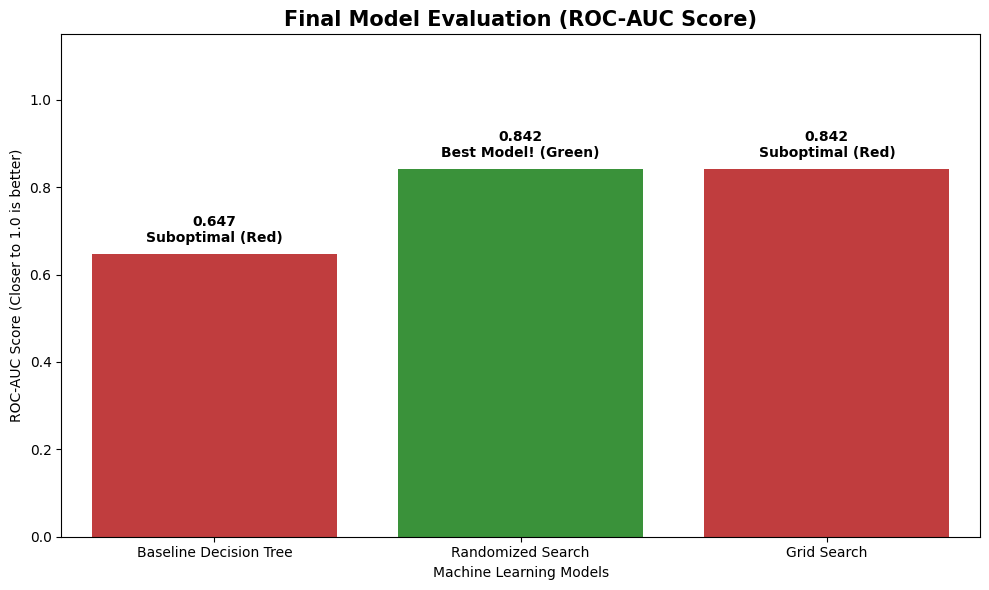


--- Detailed Final Evaluation Metrics ---


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Baseline Decision Tree,0.7197,0.4730,0.4920,0.4823,0.6467
1,Randomized Search,0.7999,0.6620,0.5027,0.5714,0.8416
2,Grid Search,0.8013,0.6643,0.5080,0.5758,0.8416


In [10]:

import matplotlib.pyplot as plt
import seaborn as sns

best_index = results_df['ROC-AUC'].idxmax()

bar_colors = [
    '#2ca02c' if i == best_index else '#d62728'
    for i in range(len(results_df))
]

plt.figure(figsize=(10, 6))

sns.barplot(
    x='Model',
    y='ROC-AUC',
    data=results_df,
    hue='Model',
    palette=bar_colors,
    legend=False
)

for index, row in results_df.iterrows():
    label = 'Best Model! (Green)' if index == best_index else 'Suboptimal (Red)'

    plt.text(
        index,
        row['ROC-AUC'] + 0.02,
        f"{row['ROC-AUC']:.3f}\n{label}",
        color='black',
        ha='center',
        va='bottom',
        fontweight='bold',
        fontsize=10
    )

plt.title(
    'Final Model Evaluation (ROC-AUC Score)',
    fontsize=15,
    fontweight='bold'
)

plt.ylabel('ROC-AUC Score (Closer to 1.0 is better)')
plt.xlabel('Machine Learning Models')
plt.ylim(0, 1.15)
plt.tight_layout()
plt.show()

print("\n--- Detailed Final Evaluation Metrics ---")
display(results_df.round(4))
